# SoccerNet EDA

Looking at the SoccerNet features and labels (ResNET_TF2_PCA512 + Labels-v2). Nothing on StatsBomb or modelling in here.

Note that "all games" means the 100 games I downloaded. The download script only pulls the `valid` split, so none of this describes the full SoccerNet set. Loaders are in `src/data_loaders.py` and figures go to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

# run from the repo root so the data/raw/... paths work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loaders as dl

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# chart styling
BAR = "#2a6fb0"
INK, MUTED, GRID = "#1f2328", "#59636e", "#d8dee4"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def save(fig, name):
    p = FIG_DIR / name
    fig.savefig(p, bbox_inches="tight", facecolor="white")
    print("saved", p.relative_to(ROOT))

## 1. Game inventory

In [2]:
games = list(dl.iter_games())
inv = pd.DataFrame([{"league": g.league, "season": g.season, "game": g.game} for g in games])
print(f"{len(inv)} games | {inv.league.nunique()} leagues | {inv.groupby(['league','season']).ngroups} league-seasons")
by_ls = inv.groupby(["league", "season"]).size().rename("games").reset_index()
by_ls

100 games | 6 leagues | 17 league-seasons


,league,season,games
0,england_epl,2014-2015,1
1,england_epl,2015-2016,12
2,england_epl,2016-2017,6
3,europe_uefa-champions-league,2014-2015,8
4,europe_uefa-champions-league,2015-2016,10
5,europe_uefa-champions-league,2016-2017,2
6,france_ligue-1,2015-2016,1
7,france_ligue-1,2016-2017,8
8,germany_bundesliga,2014-2015,2
9,germany_bundesliga,2015-2016,4


saved reports\figures\01_games_per_league.png


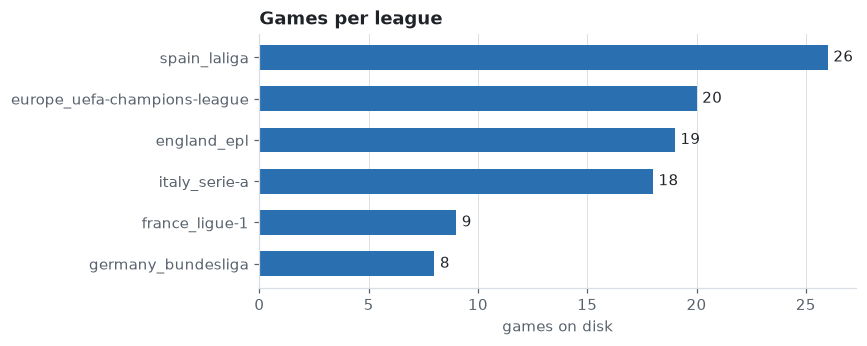

In [3]:
by_league = inv.groupby("league").size().sort_values().rename("games")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(by_league.index, by_league.values, color=BAR, height=0.6)
for y, v in enumerate(by_league.values):
    ax.text(v + by_league.max() * 0.01, y, str(v), va="center", color=INK)
ax.set_xlabel("games on disk"); ax.set_title("Games per league")
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "01_games_per_league.png"); plt.show()

## 2. Feature arrays

In [4]:
fs = dl.build_feature_summary()
present = fs[fs.file_present]
print(f"{len(fs)} (game, half) slots; {len(present)} arrays present")
print("feature_dim values:", present.feature_dim.unique().tolist(), "| dtypes:", present.dtype.unique().tolist())
print(f"total frames: {int(present.n_frames.sum()):,}")
present.groupby("half")["n_frames"].describe().round(1)

200 (game, half) slots; 200 arrays present
feature_dim values: [512] | dtypes: ['float32']
total frames: 1,097,997


,count,mean,std,min,25%,50%,75%,max
half,,,,,,,,
1,100.0,5435.4,97.0,5399.0,5400.0,5400.0,5400.0,5922.0
2,100.0,5544.6,193.5,5399.0,5400.0,5400.0,5739.2,6118.0


In [5]:
present[["n_frames", "min", "max", "mean", "std", "n_nan", "n_inf"]].describe().round(3)

,n_frames,min,max,mean,std,n_nan,n_inf
count,200.000,200.000,200.000,200.000,200.000,200.0,200.0
mean,5489.985,-33.230,29.191,0.001,1.355,0.0,0.0
std,162.205,0.720,2.797,0.018,0.050,0.0,0.0
min,5399.000,-36.033,22.748,-0.044,1.223,0.0,0.0
25%,5400.000,-33.714,27.146,-0.012,1.321,0.0,0.0
50%,5400.000,-33.175,29.209,-0.001,1.352,0.0,0.0
75%,5507.250,-32.717,31.068,0.013,1.394,0.0,0.0
max,6118.000,-31.105,39.077,0.052,1.490,0.0,0.0


saved reports\figures\02_feature_summaries.png


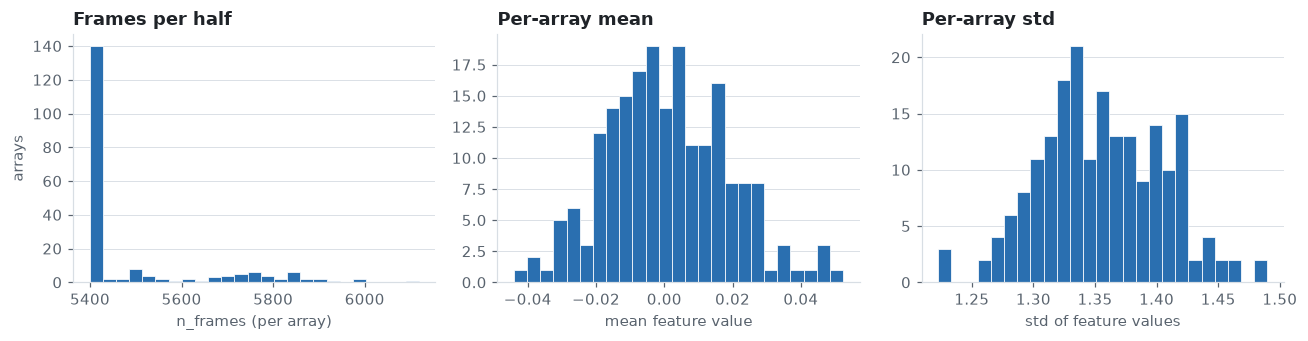

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(present.n_frames, bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[0].set_title("Frames per half"); axes[0].set_xlabel("n_frames (per array)"); axes[0].set_ylabel("arrays")
axes[1].hist(present["mean"], bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[1].set_title("Per-array mean"); axes[1].set_xlabel("mean feature value")
axes[2].hist(present["std"], bins=25, color=BAR, edgecolor="white", lw=0.5)
axes[2].set_title("Per-array std"); axes[2].set_xlabel("std of feature values")
for a in axes: a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); save(fig, "02_feature_summaries.png"); plt.show()

distinct array shapes (frames x dim): 62 distinct frame counts; dim = [512]
count      100.0
mean     10980.0
std        208.5
min      10798.0
25%      10800.0
50%      10892.0
75%      11157.0
max      11598.0
games with exactly 5400 frames in both halves (90.0 min): 34


saved reports\figures\06_frames_per_game.png


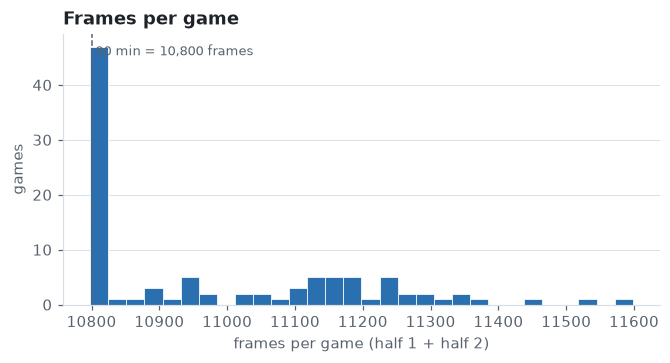

In [7]:
# frames per game (both halves added) and array shapes
per_game = present.groupby("game_id")["n_frames"].sum()
print("distinct array shapes (frames x dim):", present.groupby(["n_frames"]).ngroups, "distinct frame counts; dim =", present.feature_dim.unique().tolist())
print(per_game.describe().round(1).to_string())
print(f"games with exactly 5400 frames in both halves (90.0 min): {(present.groupby('game_id').n_frames.apply(lambda s: (s == 5400).all())).sum()}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_game, bins=30, color=BAR, edgecolor="white", lw=0.5)
ax.axvline(10800, color=MUTED, lw=1, ls="--"); ax.text(10800, ax.get_ylim()[1] * 0.92, " 90 min = 10,800 frames", color=MUTED, fontsize=8.5)
ax.set_xlabel("frames per game (half 1 + half 2)"); ax.set_ylabel("games"); ax.set_title("Frames per game")
ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "06_frames_per_game.png"); plt.show()

sampled frames: (10000, 512)


saved reports\figures\03_feature_value_distribution.png


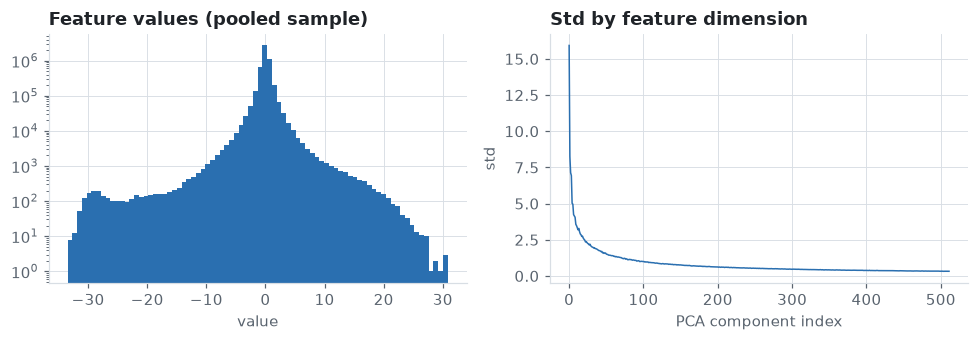

In [8]:
# pooled value distribution, from a random sample of frames so we don't load everything at once
rng = np.random.default_rng(0)
sample = []
for g in games:
    for h, f in enumerate(dl.load_game(g, mmap=True)["features"], start=1):
        if f is not None and len(f):
            idx = np.sort(rng.choice(len(f), size=min(50, len(f)), replace=False))
            sample.append(np.asarray(f[idx]))
sample = np.concatenate(sample)
print("sampled frames:", sample.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(sample.ravel(), bins=80, color=BAR, edgecolor="none")
axes[0].set_title("Feature values (pooled sample)"); axes[0].set_xlabel("value"); axes[0].set_yscale("log")
axes[1].plot(sample.std(axis=0), color=BAR, lw=1)
axes[1].set_title("Std by feature dimension"); axes[1].set_xlabel("PCA component index"); axes[1].set_ylabel("std")
for a in axes: a.grid(color=GRID, lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); save(fig, "03_feature_value_distribution.png"); plt.show()

## 3. Annotations and class imbalance

In [9]:
ann = dl.build_annotation_table()
tbl = dl.class_count_table(ann)
print(f"{len(ann):,} annotations | {ann.game_id.nunique()} games | {ann.label.nunique()} distinct labels (expected 17)")
tbl.assign(share=(tbl.share * 100).round(2)).rename(columns={"share": "share_%"})

21,447 annotations | 100 games | 17 distinct labels (expected 17)


,count,n_games,share_%
label,,,
Ball out of play,6253,100,29.16
Throw-in,3718,100,17.34
Foul,2176,100,10.15
Indirect free-kick,1907,99,8.89
Clearance,1516,100,7.07
Shots on target,1182,100,5.51
Shots off target,984,100,4.59
Corner,953,100,4.44
Substitution,560,100,2.61


In [10]:
nonzero = tbl[tbl["count"] > 0]
imb = nonzero["count"].max() / nonzero["count"].min()
print(f"Most common: {nonzero.index[0]} ({nonzero['count'].iloc[0]:,}); rarest: {nonzero.index[-1]} ({nonzero['count'].iloc[-1]:,})")
print(f"Imbalance ratio (max/min): {imb:,.0f}x")
print(f"Top 3 classes hold {tbl.share.head(3).sum():.1%} of annotations; bottom 3 hold {tbl.share.tail(3).sum():.2%}")

# rare = under 1% of annotations, or in fewer than half the games
RARE_SHARE = 0.01
rare = tbl[(tbl.share < RARE_SHARE) | (tbl.n_games < len(games) / 2)]
print(f"\nRARE classes (< {RARE_SHARE:.0%} of annotations or in < 50% of games):")
print(rare.assign(share=(rare.share * 100).round(2)).rename(columns={"share": "share_%"}).to_string())
print(f"Annotations per game for rare classes: " + ", ".join(f"{k} {tbl.loc[k,'count']/len(games):.2f}" for k in rare.index))

Most common: Ball out of play (6,253); rarest: Yellow->red card (8)
Imbalance ratio (max/min): 782x
Top 3 classes hold 56.6% of annotations; bottom 3 hold 0.27%

RARE classes (< 1% of annotations or in < 50% of games):
                  count  n_games  share_%
label                                    
Penalty              36       32     0.17
Red card             13       12     0.06
Yellow->red card      8        8     0.04
Annotations per game for rare classes: Penalty 0.36, Red card 0.13, Yellow->red card 0.08


saved reports\figures\04_class_balance.png


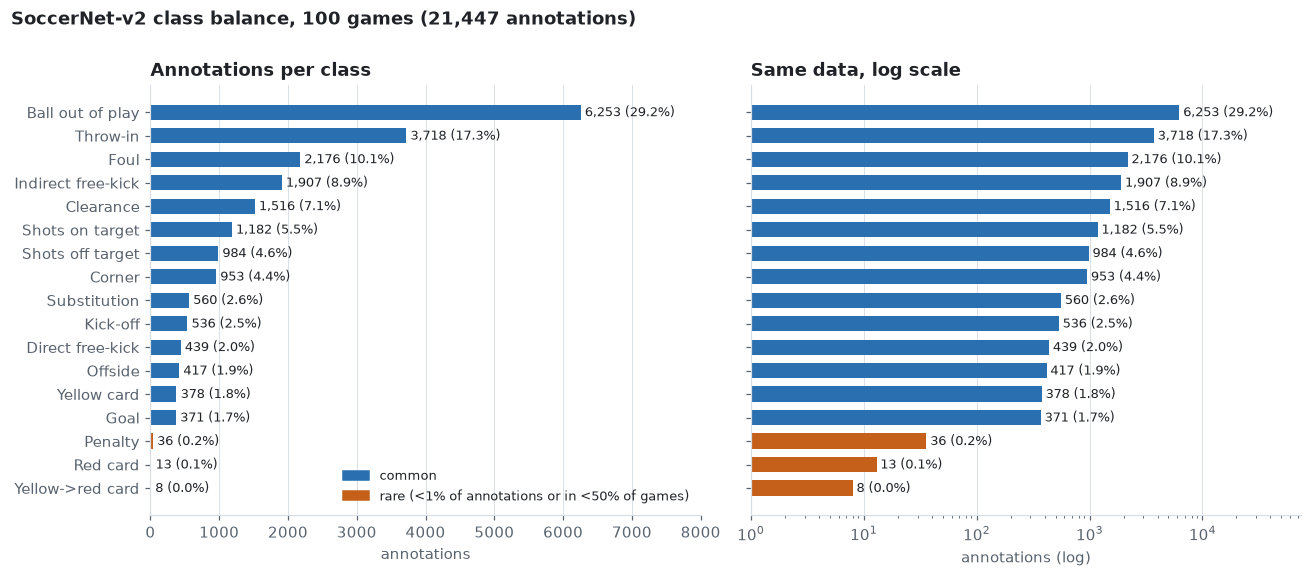

In [11]:
from matplotlib.patches import Patch
RARE_C = "#c4601a"
t = tbl.iloc[::-1]  # ascending so the largest bar is on top of a horizontal chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, log in zip(axes, (False, True)):
    ax.barh(t.index, t["count"], height=0.65,
            color=[RARE_C if c in rare.index else BAR for c in t.index])
    for y, (c, s) in enumerate(zip(t["count"], t["share"])):
        ax.text(c * (1.08 if log else 1) + (0 if log else t["count"].max() * 0.01), y,
                f"{c:,} ({s:.1%})", va="center", fontsize=8.5, color=INK)
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    if log:
        ax.set_xscale("log"); ax.set_xlim(1, t["count"].max() * 12)
        ax.set_title("Same data, log scale"); ax.set_xlabel("annotations (log)")
    else:
        ax.set_xlim(0, t["count"].max() * 1.28)
        ax.set_title("Annotations per class"); ax.set_xlabel("annotations")
fig.suptitle(f"SoccerNet-v2 class balance, {ann.game_id.nunique()} games ({len(ann):,} annotations)",
             x=0.01, ha="left", fontweight="bold", y=1.0)
axes[0].legend(handles=[Patch(color=BAR, label="common"), Patch(color=RARE_C, label="rare (<1% of annotations or in <50% of games)")],
               loc="lower right", frameon=False, fontsize=8.5)
fig.tight_layout(); save(fig, "04_class_balance.png"); plt.show()

saved reports\figures\05_class_coverage.png


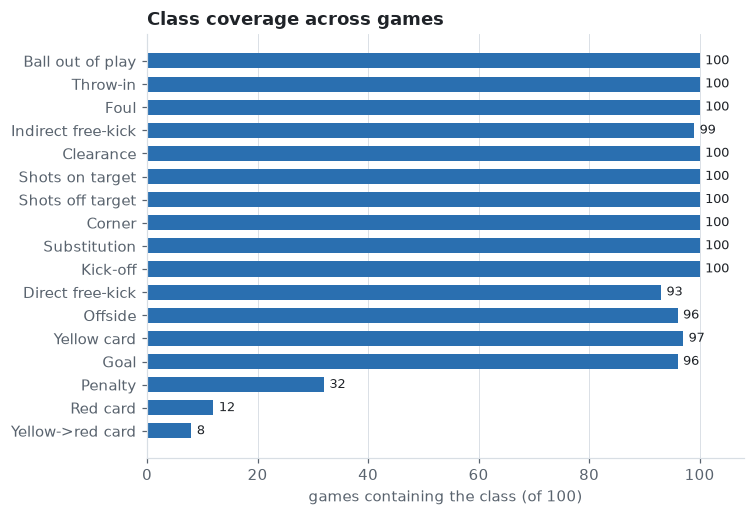

In [12]:
# how many games each class shows up in
g = tbl["n_games"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(g.index, g.values, color=BAR, height=0.65)
for y, v in enumerate(g.values):
    ax.text(v + 1, y, str(v), va="center", fontsize=8.5)
ax.set_xlim(0, ann.game_id.nunique() * 1.08)
ax.set_xlabel(f"games containing the class (of {ann.game_id.nunique()})"); ax.set_title("Class coverage across games")
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "05_class_coverage.png"); plt.show()

## 4. Data quality

In [13]:
checks = {}

# missing files
checks["games with a missing feature file"] = int((~fs.file_present).groupby(fs.game_id).any().sum())
checks["games missing Labels-v2.json"] = sum(not (g.path / dl.LABELS_FILE).exists() for g in games)

# empty or odd arrays
checks["empty arrays (0 frames)"] = int((present.n_frames == 0).sum())
checks["arrays with unexpected feature_dim != 512"] = int((present.feature_dim != 512).sum())
checks["arrays containing NaN"] = int((present.n_nan > 0).sum())
checks["arrays containing Inf"] = int((present.n_inf > 0).sum())
checks["arrays with zero variance"] = int((present["std"] == 0).sum())

# labels
n_ann_per_game = ann.groupby("game_id").size()
checks["games with zero annotations"] = len(games) - n_ann_per_game.size
checks["annotations with unknown class"] = int((~ann.label.isin(dl.CLASSES_V2)).sum())
checks["annotations with null label/time/position"] = int(
    ann[["label", "half", "seconds", "position_ms"]].isna().any(axis=1).sum())
checks["annotations with half not in {1,2}"] = int((~ann.half.isin([1, 2])).sum())
checks["exact duplicate annotations"] = int(ann.duplicated(["game_id", "label", "half", "position_ms", "team"]).sum())
checks["visibility values"] = ann.visibility.value_counts().to_dict()

# last label time vs feature length (~2 frames/sec, so n_frames / 2 = seconds)
rate = 2.0
half_len = present.set_index(["game_id", "half"])["n_frames"] / rate
last = ann.groupby(["game_id", "half"])["seconds"].max()
j = pd.concat([last.rename("last_label_s"), half_len.rename("feature_s")], axis=1).dropna()
over = j[j.last_label_s > j.feature_s + 1]
checks["(game,half) where last label is after end of features (+1s)"] = len(over)

pd.Series(checks, name="result").to_frame()

,result
games with a missing feature file,0
games missing Labels-v2.json,0
empty arrays (0 frames),0
arrays with unexpected feature_dim != 512,0
arrays containing NaN,0
arrays containing Inf,0
arrays with zero variance,0
games with zero annotations,0
annotations with unknown class,0
annotations with null label/time/position,0


In [14]:
# minutes covered per half, should be around 45+
(present.assign(minutes=present.n_frames / rate / 60)
        .groupby("half")["minutes"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
half,,,,,,,,
1,100.0,45.3,0.8,45.0,45.0,45.0,45.0,49.4
2,100.0,46.2,1.6,45.0,45.0,45.0,47.8,51.0


In [15]:
over.head(10) if len(over) else "No label timestamps exceed the feature length." 

'No label timestamps exceed the feature length.'

### Label JSON schema

In [16]:
sch = dl.audit_label_schema()
print("games with unreadable Labels-v2.json:", int((~sch.file_ok).sum()))
print("top-level keys expected:", sorted(dl.EXPECTED_TOP_KEYS))
print("games with extra/missing top-level keys:", int((sch.extra_top_keys != "").sum()), "/", int((sch.missing_top_keys != "").sum()))
print(sch[["n_annotations", "n_ann_bad_keys", "n_bad_gametime", "n_bad_position", "n_time_mismatch", "n_bad_team", "n_url_mismatch"]].sum().to_string())
print("\nvalue sets -> team:", ann.team.value_counts().to_dict())
print("               visibility:", ann.visibility.value_counts().to_dict())
print("\nlabels carrying team='not applicable':", ann.loc[ann.team == "not applicable", "label"].value_counts().to_dict())
print("annotations per game: min %d / median %d / max %d" % (sch.n_annotations.min(), sch.n_annotations.median(), sch.n_annotations.max()))

games with unreadable Labels-v2.json: 0
top-level keys expected: ['UrlLocal', 'UrlYoutube', 'annotations', 'gameAwayTeam', 'gameDate', 'gameHomeTeam', 'gameScore']
games with extra/missing top-level keys: 0 / 0
n_annotations      21447
n_ann_bad_keys         0
n_bad_gametime         0
n_bad_position         0
n_time_mismatch        0
n_bad_team             0
n_url_mismatch         0

value sets -> team: {'home': 7739, 'away': 7455, 'not applicable': 6253}
               visibility: {'visible': 17491, 'not shown': 3956}

labels carrying team='not applicable': {'Ball out of play': 6253}
annotations per game: min 125 / median 216 / max 290


In [17]:
# labels at exactly 0:00 of a half (fine for kick-off, suspicious for anything else)
zero = ann[ann.seconds == 0]
z = zero.groupby(["label", "half"]).size().unstack(fill_value=0)
print("annotations stamped at 0:00 of a half, by class and half:"); print(z.to_string())
sub = ann[ann.label == "Substitution"]
print(f"\nSubstitutions at 0:00: {(sub.seconds == 0).sum()} of {len(sub)} ({(sub.seconds == 0).mean():.1%}); of those 'not shown': {((sub.seconds == 0) & (sub.visibility == 'not shown')).sum()}")
dup_cols = ["game_id", "label", "half", "position_ms", "team"]
dups = ann[ann.duplicated(dup_cols, keep=False)]
print(f"\nexact duplicate rows (same game/label/half/time/team): {ann.duplicated(dup_cols).sum()} extra rows across {dups.game_id.nunique()} games; by class: {dups.label.value_counts().to_dict()}")

annotations stamped at 0:00 of a half, by class and half:
half              1.0  2.0
label                     
Ball out of play    0    1
Kick-off           96   93
Substitution        0   41

Substitutions at 0:00: 41 of 560 (7.3%); of those 'not shown': 36

exact duplicate rows (same game/label/half/time/team): 7 extra rows across 6 games; by class: {'Substitution': 10, 'Foul': 2, 'Shots on target': 2}


## 5. Class mix by league and season

In [18]:
ct = pd.crosstab(ann.league, ann.label).reindex(columns=tbl.index)          # counts
share = ct.div(ct.sum(axis=1), axis=0) * 100                                   # within-league class share (%)
n_games_league = inv.groupby("league").size()
summary = pd.DataFrame({"games": n_games_league, "annotations": ct.sum(axis=1)})
summary["ann_per_game"] = (summary.annotations / summary.games).round(1)
summary = summary.sort_values("games", ascending=False)
print(summary.to_string())
print("\nwithin-league class share (%), columns ordered by overall count:")
print(share.loc[summary.index].round(1).to_string())
print("\nrare-class counts by league:")
print(ct.loc[summary.index, [c for c in tbl.index if c in rare.index]].to_string())

                              games  annotations  ann_per_game
league                                                        
spain_laliga                     26         5683         218.6
europe_uefa-champions-league     20         4357         217.8
england_epl                      19         3808         200.4
italy_serie-a                    18         3986         221.4
france_ligue-1                    9         1827         203.0
germany_bundesliga                8         1786         223.2

within-league class share (%), columns ordered by overall count:
label                         Ball out of play  Throw-in  Foul  Indirect free-kick  Clearance  Shots on target  Shots off target  Corner  Substitution  Kick-off  Direct free-kick  Offside  Yellow card  Goal  Penalty  Red card  Yellow->red card
league                                                                                                                                                                                    

saved reports\figures\07_class_share_by_league.png


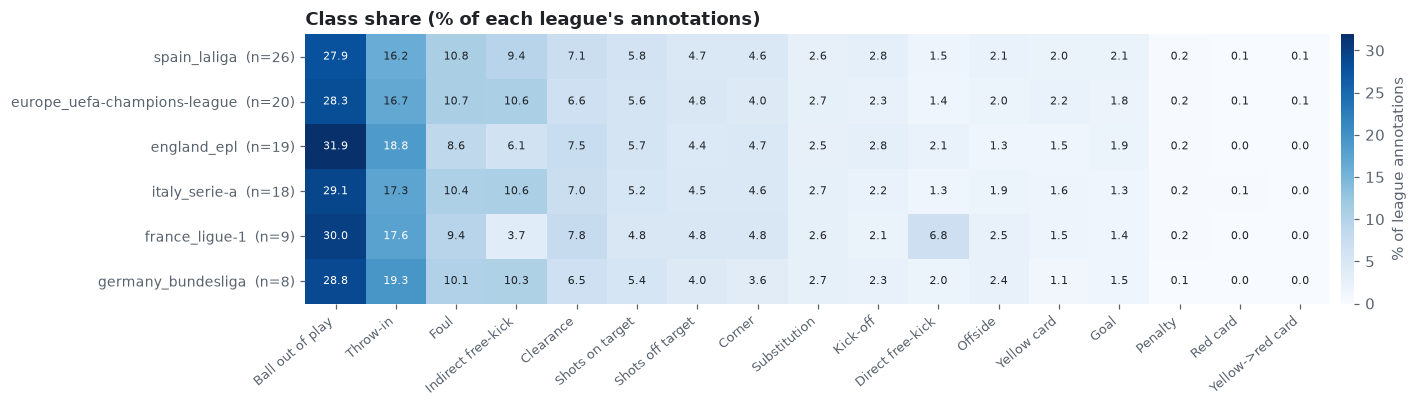

In [19]:
order = summary.index
data = share.loc[order]
fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(data.values, aspect="auto", cmap="Blues", vmin=0, vmax=data.values.max())
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(data.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels([f"{l}  (n={n_games_league[l]})" for l in order], fontsize=9)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if v > data.values.max() * 0.55 else INK)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Class share (% of each league's annotations)")
cb = fig.colorbar(im, ax=ax, pad=0.01, fraction=0.025); cb.set_label("% of league annotations", color=MUTED); cb.outline.set_visible(False)
fig.tight_layout(); save(fig, "07_class_share_by_league.png"); plt.show()

saved reports\figures\08_games_per_league_season.png


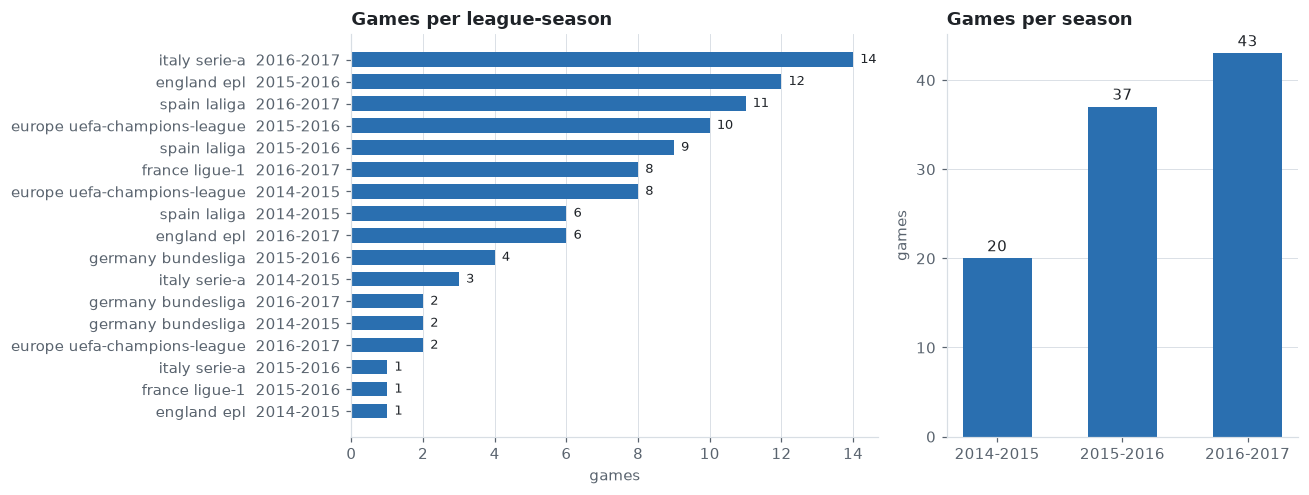

In [20]:
ls = inv.groupby(["league", "season"]).size().rename("games").reset_index()
ls["label"] = ls.league.str.replace("_", " ") + "  " + ls.season
ls = ls.sort_values("games")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [3, 2]})
axes[0].barh(ls.label, ls.games, color=BAR, height=0.65)
for y, v in enumerate(ls.games): axes[0].text(v + 0.2, y, str(v), va="center", fontsize=8.5)
axes[0].set_xlabel("games"); axes[0].set_title("Games per league-season")
season_g = inv.groupby("season").size()
axes[1].bar(season_g.index, season_g.values, color=BAR, width=0.55)
for x, v in enumerate(season_g.values): axes[1].text(x, v + 0.8, str(v), ha="center")
axes[1].set_ylabel("games"); axes[1].set_title("Games per season")
for a, ax_ in zip(axes, ("x", "y")): a.grid(axis=ax_, color=GRID, lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); save(fig, "08_games_per_league_season.png"); plt.show()

In [21]:
# chi-square on league x class counts
from math import isfinite
obs = ct.values.astype(float)
exp = obs.sum(axis=1, keepdims=True) * obs.sum(axis=0, keepdims=True) / obs.sum()
chi2 = ((obs - exp) ** 2 / exp).sum(); dof = (obs.shape[0] - 1) * (obs.shape[1] - 1)
cramers_v = np.sqrt(chi2 / (obs.sum() * (min(obs.shape) - 1)))
print(f"chi2={chi2:,.0f} (dof={dof}); Cramer's V = {cramers_v:.3f}  (effect size: ~0.1 small, ~0.3 medium)")
season_ct = pd.crosstab(ann.season, ann.label)
o2 = season_ct.values.astype(float); e2 = o2.sum(axis=1, keepdims=True) * o2.sum(axis=0, keepdims=True) / o2.sum()
print(f"season x class Cramer's V = {np.sqrt(((o2 - e2) ** 2 / e2).sum() / (o2.sum() * (min(o2.shape) - 1))):.3f}")
lift = (share / (ct.sum(axis=0) / ct.values.sum() * 100)).loc[summary.index]
print("\nlargest league-vs-overall deviations (share / overall share), classes with >= 100 annotations:")
big = lift.loc[:, ct.sum(axis=0) >= 100].stack().rename("lift").reset_index()
big.columns = ["league", "label", "lift"]
big["dev"] = (big.lift - 1).abs()
print(big.sort_values("dev", ascending=False).head(6)[["league", "label", "lift"]].round(2).to_string(index=False))

chi2=470 (dof=80); Cramer's V = 0.066  (effect size: ~0.1 small, ~0.3 medium)
season x class Cramer's V = 0.049

largest league-vs-overall deviations (share / overall share), classes with >= 100 annotations:
                      league              label  lift
              france_ligue-1   Direct free-kick  3.32
              france_ligue-1 Indirect free-kick  0.42
          germany_bundesliga        Yellow card  0.60
               italy_serie-a   Direct free-kick  0.61
                 england_epl            Offside  0.65
europe_uefa-champions-league   Direct free-kick  0.68


## 6. Takeaways

- The classes are very uneven. Ball out of play is 29% of the 21,447 annotations and the top three classes are 57%. The rarest are Penalty (36, in 32 games), Red card (13, in 12 games) and Yellow->red card (8, in 8 games), about 0.3% together. Accuracy won't tell us much here. Macro-F1 or per-class recall, class weights, and splitting by game (so a rare class doesn't end up with no test examples) seem like the way to go.
- The features look fine. 200 arrays (100 games, 2 halves), all 512-d float32, about 1.1M frames at roughly 2 fps. No NaNs, infs, empty arrays or missing files, and no label falls after the end of its feature array.
- The labels are mostly consistent but have a few quirks. `team` is "not applicable" on every Ball out of play row. 41 Substitutions (7.3%) are stamped 0:00 of the second half, 36 of them "not shown", which looks like a placeholder time and would line them up with the wrong frames. There are also 7 exact duplicate rows. We need to decide whether to drop these before training.
- The sample is lopsided across leagues, but the class mix is similar. La Liga has 26 games and the Champions League 20, against 8 for Bundesliga and 9 for Ligue 1, and 2016-17 has 43 games to 20 for 2014-15. League and season explain very little of the class mix (Cramer's V 0.066 and 0.049). The exception is Ligue 1, with 6.8% Direct free-kick and 3.7% Indirect free-kick, versus roughly 1-2% and 6-11% in the other leagues. That could be the annotators mixing up the two free-kick types, though it's only 9 games. Rare classes are too sparse to evaluate per league (Bundesliga has 2 penalties and no red cards).

This is the `valid` split only, not all of SoccerNet.